In [2]:
!pip install tensorflow

  Using cached tensorflow-2.19.0-cp312-cp312-win_amd64.whl.metadata (4.1 kB)
  Using cached absl_py-2.2.2-py3-none-any.whl.metadata (2.6 kB)
  Using cached astunparse-1.6.3-py2.py3-none-any.whl.metadata (4.4 kB)
  Using cached flatbuffers-25.2.10-py2.py3-none-any.whl.metadata (875 bytes)
  Using cached gast-0.6.0-py3-none-any.whl.metadata (1.3 kB)
  Using cached google_pasta-0.2.0-py3-none-any.whl.metadata (814 bytes)
  Using cached libclang-18.1.1-py2.py3-none-win_amd64.whl.metadata (5.3 kB)
  Using cached opt_einsum-3.4.0-py3-none-any.whl.metadata (6.3 kB)
  Using cached termcolor-3.0.1-py3-none-any.whl.metadata (6.1 kB)
  Using cached grpcio-1.71.0-cp312-cp312-win_amd64.whl.metadata (4.0 kB)
  Using cached tensorboard-2.19.0-py3-none-any.whl.metadata (1.8 kB)
  Using cached keras-3.9.2-py3-none-any.whl.metadata (6.1 kB)
  Using cached ml_dtypes-0.5.1-cp312-cp312-win_amd64.whl.metadata (22 kB)
  Using cached namex-0.0.9-py3-none-any.whl.metadata (322 bytes)
  Using cached optree-0.15

In [ ]:
#libraries
import os
import csv
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.svm import SVC
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.models import Sequential
from sklearn.tree import DecisionTreeClassifier
from tensorflow.keras.applications import VGG16
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.optimizers import Adam, SGD
from tensorflow.keras.applications import ResNet50
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier, AdaBoostClassifier
from tensorflow.keras.layers import Dense, Input, Conv2D, MaxPooling2D, BatchNormalization, Flatten, Dropout
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_curve, auc


path_of_csv_file = "C:/Users/Than/Desktop/diko_mas_2025/machine-learning-undergraduate-course-cse-uoi-gr/Test-IDs.csv"
path_of_test_images = "C:/Users/Than/Desktop/diko_mas_2025/machine-learning-undergraduate-course-cse-uoi-gr/TEST_images/TEST_images"
path_of_train_images = "C:/Users/Than/Desktop/diko_mas_2025/machine-learning-undergraduate-course-cse-uoi-gr/train-images/train"


# φόρτωση εικόνων εκπαίδευσης από τους φακέλους "pleasant" και "unpleasant" με μέγιστο αριθμό εικόνων ανά κατηγορία
images, labels = [], []
max_images_per_category = 2
for expression in ["unpleasant", "pleasant"]:
    folder = os.path.join(path_of_train_images, expression) 

    # filenames = os.listdir(folder) # ετσι φορτώνονται ολες οι train eikones
    filenames = os.listdir(folder)[:max_images_per_category] # φορ΄τώνει max_images_per_category eikones απο καθε κατηγορία
    for filename in filenames:
        img_path = os.path.join(folder, filename)
        img = load_img(img_path, target_size=(64, 64)) #μεγεθος καθε εικονας 64x64
        images.append(img_to_array(img))
        labels.append(expression)

x = np.array(images) / 255.0  # τιμες φωτεινοτητας απο 0 εως 255 (κανονικοποιηση τιμων pixel)

y = np.array(labels) 
# μετατροπή των ετικετών κειμένου ("unpleasant", "pleasant") σε αριθμητικές τιμές (0 και 1)
y = LabelEncoder().fit_transform(y)



In [ ]:
# Ελεγχος

print (x.shape) # (2 * max_images_per_category, 64, 64, 3), δηλαδή εικόνες 64x64 με 3 κανάλια χρώματος(R,G,B)
# τιμη x ειναι απο 0 εως 255

print (y.shape) # (2 * max_images_per_category,), δηλαδή μία ετικέτα (0 ή 1) για κάθε εικόνα
# τιμη y ειναι 0 ή 1

In [ ]:
# Δημιουργία validation συνόλου με βάση το αρχείο CSV με τα IDs για το τελικό τεστ

# αναγνωση του αρχειου CSV και φορτωση των αντιστοιχων εικονων για το validation set
test_ids = []
filenames_csv = []

with open(path_of_csv_file, mode="r", newline='', encoding="utf-8-sig") as file:
    reader = csv.DictReader(file)
    
    for row in reader:
        row = {key.strip(): value for key, value in row.items()}
        test_ids.append(row["ID"])
        filenames_csv.append(row["Filename"])

validation = []
for f in filenames_csv:
    img_path = os.path.join(path_of_test_images, f)
    if os.path.exists(img_path):
        img = load_img(img_path, target_size=(64, 64))
        img_array = img_to_array(img)
        img_array = img_array
        validation.append(img_array)
validation = np.array(validation) / 255.0

In [ ]:
# Προβλεψη ετικετων για το validation set και δημιουργια αρχειου αποτελεσματων
y_pred_prob = best_model.predict(validation)

results_df = pd.DataFrame({
     "ID": test_ids,
     "LABEL": y_pred_prob.flatten()  # μετατροπη των προβλεψεων σε μονοδιαστατο πινακα
})

results_df["LABEL"] = results_df["LABEL"].apply(lambda x: 1 if x >= 0.5 else 0)
results_df.to_csv("preds.csv", index=False)

In [4]:
# Εξαγωγη χαρακτηριστικων απο το συνολο εικονων με χρηση του ResNet50 (pretrained CNN) για χρήση στους υπολοιπους ταξινομητες


# φόρτωση του pretrained μοντελου ResNet50 χωρις τα τελικα classification layers
resnet = ResNet50(weights="imagenet", include_top=False, input_shape=(64, 64, 3)) 
                                                       
resnet.trainable = False
global_average_layer = tf.keras.layers.GlobalAveragePooling2D()

# προεπεξεργασια των εικονων εκπαιδευσης για να ειναι συμβατες με το ResNet50
x = preprocess_input(x)                                
feature_map = resnet.predict(x) # εξαγωγη χαρακτηριστικων απο το ResNet50
x = global_average_layer(feature_map).numpy()  # μετατροπη του σχηματος απο (n, 64, 64, 3) σε (n, 2048)
                                                       

# προεπεξεργασια του validation set με τον ιδιο τροπο
validation = preprocess_input(validation)
feature_map = resnet.predict(validation)
validation = global_average_layer(feature_map).numpy() # μετατροπη του σχηματος απο (n, 64, 64, 3) σε (n, 2048)
                                                       
    


4/4 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step  
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 208ms/step


In [5]:
# Έλεγχος

print (x.shape) # (2 * max_images_per_category, 2048) 
# τιμη x ειναι απο 0 εως 255

print (y.shape) # (2 * max_images_per_category,) όπου κάθε τιμή είναι 0 (unpleasant) ή 1 (pleasant)
# τιμη y ειναι 0 ή 1

(100, 2048)
(100,)


2 cosine 0.7
2 manhattan 0.7481203007518797
2 euclidean 0.7
4 cosine 0.8511278195488721
4 manhattan 0.8
4 euclidean 0.8
6 cosine 0.751918158567775
6 manhattan 0.8020202020202021
6 euclidean 0.751918158567775
8 cosine 0.8
8 manhattan 0.8
8 euclidean 0.8
Highest F1 score= 0.8511278195488721, using k= 4, with best distance metric= cosine
Accuracy= 0.83
Recall= 0.8
Confusion Matrix=
[[43  7]
 [10 40]]
Precision= 0.851063829787234
F1-score= 0.8298468621759583


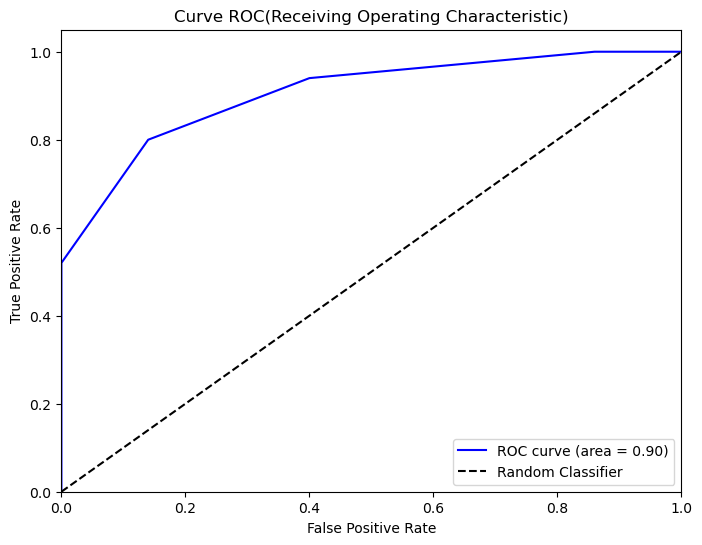

In [23]:
#K-Nearest Neighbors(K-NN)

k_fold= KFold(n_splits=5, shuffle=True, random_state=25)

#οι μεταβλητες που κρατανε τον καλυτερο συνδυασμο τιμων
max_f1_score= -1
best_k_value= None
best_fold= None
best_distance_metric= None

#συνδυασμοι neighbors kai metrics
for k in [2,4,6,8]:
    for metricPar in ["cosine","manhattan","euclidean"]:
        fold_f1_list= []
        #διαχωρισμος σε Train και Test για καθε fold
        for fold, (train_index, test_index) in enumerate(k_fold.split(x)):
            x_train_fold,x_test_fold= x[train_index], x[test_index]
            y_train_fold,y_test_fold= y[train_index], y[test_index]

            knn= KNeighborsClassifier(n_neighbors=k, metric=metricPar)
            y_test_pred = knn.fit(x_train_fold, y_train_fold).predict(x_test_fold)
            f1 = f1_score(y_test_fold, y_test_pred, average="weighted")
            fold_f1_list.append(f1)

        current_max_f1= np.max(fold_f1_list)
        print(k,metricPar,current_max_f1)

        if current_max_f1 > max_f1_score:
            best_k_value = k
            best_distance_metric = metricPar
            max_f1_score = current_max_f1
print(f"Highest F1 score= {max_f1_score}, using k= {best_k_value}, with best distance metric= {best_distance_metric}")        

#εκπαιδευση και προβλεψη
knn= KNeighborsClassifier(n_neighbors=best_k_value, metric=best_distance_metric)
y_pred = knn.fit(x, y).predict(x)

accuracy= accuracy_score(y, y_pred)
recall= recall_score(y, y_pred)
conf_matrix= confusion_matrix(y, y_pred)
precision= precision_score(y, y_pred)
f1= f1_score(y, y_pred, average="weighted")

print(f"Accuracy= {accuracy}")
print(f"Recall= {recall}")
print(f"Confusion Matrix=\n{conf_matrix}")
print(f"Precision= {precision}")
print(f"F1-score= {f1}")


fpr,tpr,thresholds= roc_curve(y, knn.predict_proba(x)[:, 1])
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color="blue", label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color="black", linestyle="--",label="Random Classifier")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Curve ROC(Receiving Operating Characteristic)")
plt.legend(loc="lower right")
plt.show()


# Δημιουργία αρχείου υποβολής με τις προβλέψεις του KNN μοντέλου για τα δεδομένα validation
y_pred_prob = knn.predict(validation)

results_df = pd.DataFrame({
     "ID": test_ids,
     "LABEL": y_pred_prob.flatten()  # single value for each prediction
})

results_df["LABEL"] = results_df["LABEL"].apply(lambda x: 1 if x >= 0.5 else 0)
results_df.to_csv("preds.csv", index=False)
results_df.to_excel("preds.xlsx", index=False)


        

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step
256 sigmoid <class 'keras.src.optimizers.adam.Adam'> 0.8275862068965517
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 129ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
256 relu <class 'keras.src.optimizers.adam.Adam'> 0.8
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
256 sigmoid <class 'keras.src.optimizers.sgd.SGD'> 0.7096774193548387
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step
256 relu <class 'keras.src.optimizers.

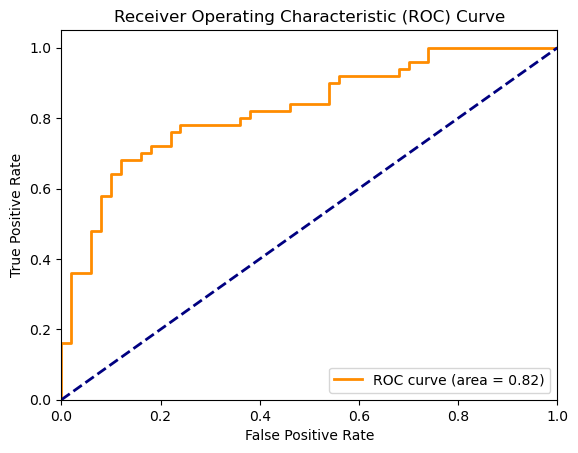

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1 256 sigmoid <keras.src.optimizers.adam.Adam object at 0x000002505DF2E1E0> 0.7407407407407407
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step
1 256 relu <keras.src.optimizers.adam.Adam object at 0x0000025057609D30> 0.72
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1 256 sigmoid <keras.src.optimizers.sgd.SGD object at 0x000002504A622180> 0.7741935483870968
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 106ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━

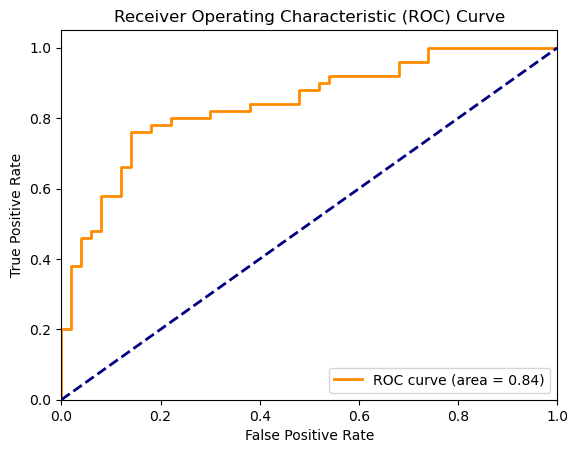

In [6]:
#Shallow and Deep Neural Networks

k_fold= KFold(n_splits=5, shuffle=True, random_state=25)

highest_f1_shallow= -1
best_shallow_combo= {}

# Shallow Neural Network(εχει 1 κρυφο επιπεδο)
hidden_layer_units_options = [256,128,64]
optimizer_choices = [Adam,SGD]
activation_functions = ["sigmoid", "relu"]

for neurons in hidden_layer_units_options:
    for optimizer_type in optimizer_choices:
        for activationPar in activation_functions:
            fold_f1_list_shallow= []

            for fold, (train_index, test_index) in enumerate(k_fold.split(x)):
                x_train_fold, x_test_fold = x[train_index], x[test_index]
                y_train_fold, y_test_fold = y[train_index], y[test_index]

                #δημιουργια Shallow Neural Network
                shallow= Sequential()
                shallow.add(Input(shape=(x_train_fold.shape[1],)))
                shallow.add(Dense(neurons, activation=activationPar)) #1 κρυφο επιπεδο
                shallow.add(Dense(1, activation="sigmoid")) #εξοδος

                #νεος optimizer
                current_optimizer= optimizer_type()
                shallow.compile(loss="binary_crossentropy", optimizer=current_optimizer, metrics=["accuracy"])
                shallow.fit(x_train_fold, y_train_fold, epochs=50, verbose=0) 

                y_pred_fold = (shallow.predict(x_test_fold) > 0.5).astype(int)

                f1= f1_score(y_test_fold, y_pred_fold)
                fold_f1_list_shallow.append(f1)
            
            megisto_f1_shallow= np.max(fold_f1_list_shallow)
            print(neurons,activationPar,optimizer_type,megisto_f1_shallow)

            if megisto_f1_shallow > highest_f1_shallow:
                highest_f1_shallow = megisto_f1_shallow
                best_shallow_combo = {"neurons": neurons, "activation": activationPar, "optimizer": optimizer_type.__name__}
print(f"Best Shallow Neural Network F1 Score: {highest_f1_shallow:.4f}")
print(f"Best Shallow Neural Network Combo: {best_shallow_combo}")

#εφαρμοζουμε το SNN στο x kai y train
best_shallow= Sequential()
best_shallow.add(Input(shape=(x.shape[1],)))
best_shallow.add(Dense(best_shallow_combo["neurons"], activation=best_shallow_combo["activation"]))
best_shallow.add(Dense(1, activation="sigmoid")) #εξοδος

if best_shallow_combo["optimizer"] == "SGD":
    best_optimizer_shallow = SGD()
elif best_shallow_combo["optimizer"] == "Adam":
    best_optimizer_shallow = Adam()

best_shallow.compile(loss="binary_crossentropy", optimizer=best_optimizer_shallow, metrics=["accuracy"])
best_shallow.fit(x, y, epochs=50, verbose=0)
y_pred_shallow = (best_shallow.predict(x) > 0.5).astype(int)

accuracy_shallow = accuracy_score(y, y_pred_shallow)
recall_shallow = recall_score(y, y_pred_shallow)
conf_matrix_shallow = confusion_matrix(y, y_pred_shallow)
precision_shallow = precision_score(y, y_pred_shallow)
f1_shallow = f1_score(y, y_pred_shallow)
fpr_shallow, tpr_shallow, _ = roc_curve(y, best_shallow.predict(x))
roc_auc_shallow = auc(fpr_shallow, tpr_shallow)

print(f"Shallow Neural Network Accuracy: {accuracy_shallow:.4f}")
print(f"Shallow Neural Network Recall: {recall_shallow:.4f}")
print(f"Shallow Neural Network Precision: {precision_shallow:.4f}")
print(f"Shallow Neural Network F1 Score: {f1_shallow:.4f}")
print(f"Shallow Neural Network ROC AUC: {roc_auc_shallow:.4f}")
print("Confusion Matrix:")
print(conf_matrix_shallow)

#θα δω αν θα το βαλουμε
plt.figure()
plt.plot(fpr_shallow, tpr_shallow, color="darkorange", lw=2, label=f"ROC curve (area = {roc_auc_shallow:.2f})")
plt.plot([0, 1], [0, 1], color="navy", lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Receiver Operating Characteristic (ROC) Curve")
plt.legend(loc="lower right")
plt.show()



# Deep Neural Network(εχει 1-4 κρυφα επιπεδα)

highest_f1_deep= -1
best_f1_combo= {}

num_of_layers=[1,2,3,4]

for layers_number in num_of_layers:
    for neurons in hidden_layer_units_options:
        for optimizer_type in optimizer_choices:
            for activationPar in activation_functions:
                fold_f1_list_deep= []

                for fold, (train_index, test_index) in enumerate(k_fold.split(x)):
                    x_train_fold, x_test_fold = x[train_index], x[test_index]
                    y_train_fold, y_test_fold = y[train_index], y[test_index]

                    deep = Sequential()
                    deep.add(Input(shape=(x_train_fold.shape[1],)))

                    deep = Sequential()
                    deep.add(Input(shape=(x_train_fold.shape[1],)))

                    for _ in range(layers_number):
                        deep.add(Dense(neurons, activation=activationPar))
                    
                    deep.add(Dense(1, activation="sigmoid")) #επιπεδο εξοδου

                    # νέος optimizer
                    current_optimizer= optimizer_type()  
                    deep.compile(loss="binary_crossentropy", optimizer=current_optimizer, metrics=["accuracy"])
                    deep.fit(x_train_fold, y_train_fold, epochs=50, verbose=0) 

                    y_pred_fold= (deep.predict(x_test_fold) > 0.5).astype(int)

                    f1= f1_score(y_test_fold, y_pred_fold)
                    fold_f1_list_deep.append(f1)
            
                megisto_f1_deep= np.max(fold_f1_list_deep)
                print(layers_number,neurons,activationPar,current_optimizer,megisto_f1_deep)

                if megisto_f1_deep > highest_f1_deep:
                    highest_f1_deep= megisto_f1_deep
                    best_deep_combo= {"layers_number": layers_number, "neurons": neurons, "activation": activationPar, "optimizer": optimizer_type.__name__}
print(f"Best Shallow Neural Network F1 Score: {highest_f1_deep:.4f}")
print(f"Best Shallow Neural Network Combo: {best_deep_combo}")

#εφαρμοζουμε το DNN στο x kai y train
best_deep = Sequential()
best_deep.add(Input(shape=(x.shape[1],)))

for _ in range(best_deep_combo["layers_number"]):
    best_deep.add(Dense(best_deep_combo["neurons"], activation=best_deep_combo["activation"]))
best_deep.add(Dense(1, activation="sigmoid")) 

if best_deep_combo["optimizer"] == "SGD":
    best_optimizer_deep = SGD()
elif best_deep_combo["optimizer"] == "Adam":
    best_optimizer_deep = Adam()

best_deep.compile(loss="binary_crossentropy", optimizer=best_optimizer_deep, metrics=["accuracy"])
best_deep.fit(x, y, epochs=50, verbose=0)
y_pred_deep = (best_deep.predict(x) > 0.5).astype(int)


accuracy_deep = accuracy_score(y, y_pred_deep)
recall_deep = recall_score(y, y_pred_deep)
conf_matrix_deep = confusion_matrix(y, y_pred_deep)
precision_deep = precision_score(y, y_pred_deep)
f1_deep = f1_score(y, y_pred_deep)
fpr_deep, tpr_deep, _ = roc_curve(y, best_deep.predict(x))
roc_auc_deep = auc(fpr_deep, tpr_deep)


print(f"Deep Neural Network Accuracy: {accuracy_deep:.4f}")
print(f"Deep Neural Network Recall: {recall_deep:.4f}")
print(f"Deep Neural Network Precision: {precision_deep:.4f}")
print(f"Deep Neural Network F1 Score: {f1_deep:.4f}")
print(f"Deep Neural Network ROC AUC: {roc_auc_deep:.4f}")
print("Confusion Matrix:")
print(conf_matrix_deep)

plt.figure()
plt.plot(fpr_deep, tpr_deep, color="darkorange", lw=2, label=f"ROC curve (area = {roc_auc_deep:.2f})")
plt.plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Receiver Operating Characteristic (ROC) Curve")
plt.legend(loc="lower right")
plt.show()
S
# Δημιουργία αρχείου υποβολής με τις προβλέψεις των Shallow and Deep μπντελων για τα δεδομένα validation
y_pred_prob = best_deep.predict(validation)  # ή best_shallow

results_df = pd.DataFrame({
     "ID": test_ids,
     "LABEL": y_pred_prob.flatten()  # single value for each prediction
})

results_df["LABEL"] = results_df["LABEL"].apply(lambda x: 1 if x >= 0.5 else 0)
results_df.to_csv("preds.csv", index=False)
results_df.to_excel("preds.xlsx", index=False)


linear 0.01 0.6703296703296703
linear 0.5 0.7
linear 5 0.8
linear 50 0.7506265664160401
sigmoid 0.01 0.6703296703296703
sigmoid 0.5 0.6703296703296703
sigmoid 5 0.6703296703296703
sigmoid 50 0.74
rbf 0.01 0.6703296703296703
rbf 0.5 0.6703296703296703
rbf 5 0.6703296703296703
rbf 50 0.696969696969697
Highest F1 score: 0.8, Highest kernel: linear, Highest C: 5
Accuracy: 0.93
Recall: 0.92
Confusion Matrix:
[[47  3]
 [ 4 46]]
Precision: 0.9387755102040817
F1-score: 0.92999299929993


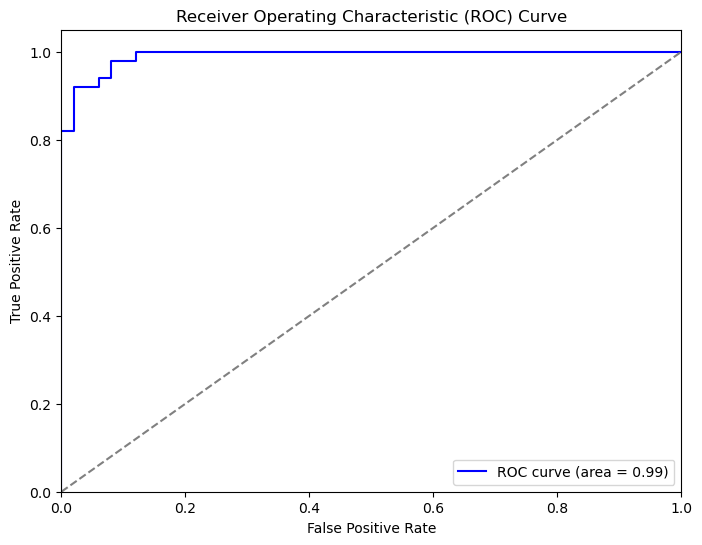

In [10]:
# Support Vector Machines(SVMs)

k_fold= KFold(n_splits=5, shuffle=True, random_state=25)

highest_f1= -1
highest_C= None
highest_kernel= None

for kernelPar in ["linear","sigmoid","rbf"]:
    for Cpar in [0.01, 0.5, 5, 50]:
        fold_f1_list= []

        for fold, (train_index, test_index) in enumerate(k_fold.split(x)):
            x_train_fold, x_test_fold = x[train_index], x[test_index]
            y_train_fold, y_test_fold = y[train_index], y[test_index]

            #δημιουργουμε SVM και στη συνεχεια κανουμε εκπαιδευση καιμ προβλεψη τις ετικετες στο test set
            svm_model= SVC(kernel=kernelPar,C=Cpar,probability=True) 
            y_test_pred= svm_model.fit(x_train_fold, y_train_fold).predict(x_test_fold)

            f1 = f1_score(y_test_fold, y_test_pred, average="weighted")
            fold_f1_list.append(f1)

        best_fold_score= np.max(fold_f1_list)
        print(kernelPar,Cpar,best_fold_score)

        if best_fold_score > highest_f1:
            highest_C = Cpar
            highest_kernel = kernelPar
            highest_f1 = best_fold_score
print(f"Highest F1 score: {highest_f1}, Highest kernel: {highest_kernel}, Highest C: {highest_C}")


#εφαρμοζουμε SVMs στο x kai y train
svm_model= SVC(kernel=highest_kernel,C=highest_C,probability=True)
y_pred= svm_model.fit(x, y).predict(x)

accuracy= accuracy_score(y, y_pred)
recall= recall_score(y, y_pred)
conf_matrix= confusion_matrix(y, y_pred)
precision= precision_score(y, y_pred)
f1= f1_score(y, y_pred, average="weighted")

print(f"Accuracy: {accuracy}")
print(f"Recall: {recall}")
print(f"Confusion Matrix:\n{conf_matrix}")
print(f"Precision: {precision}")
print(f"F1-score: {f1}")

fpr, tpr, thresholds = roc_curve(y, svm_model.predict_proba(x)[:, 1])
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color="blue", label=f"ROC curve (area = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], color="gray", linestyle="--")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Receiver Operating Characteristic (ROC) Curve")
plt.legend(loc="lower right")
plt.show()


# Δημιουργία αρχείου υποβολής με τις προβλέψεις του SVM μοντέλου για τα δεδομένα validation
y_pred_prob = svm_model.predict(validation)

results_df = pd.DataFrame({
     "ID": test_ids,
     "LABEL": y_pred_prob.flatten()  # single value for each prediction
})

results_df["LABEL"] = results_df["LABEL"].apply(lambda x: 1 if x >= 0.5 else 0)
results_df.to_csv("preds.csv", index=False)
results_df.to_excel("preds.xlsx", index=False)

10 0.7506265664160401
20 0.7
Highest F1 score Bagging: 0.7506265664160401, Best Bagging estimators: 10

Bagging
Accuracy: 0.87
Recall: 0.82
Confusion Matrix:
[[46  4]
 [ 9 41]]
Precision: 0.9111111111111111
F1-score: 0.8696741854636592


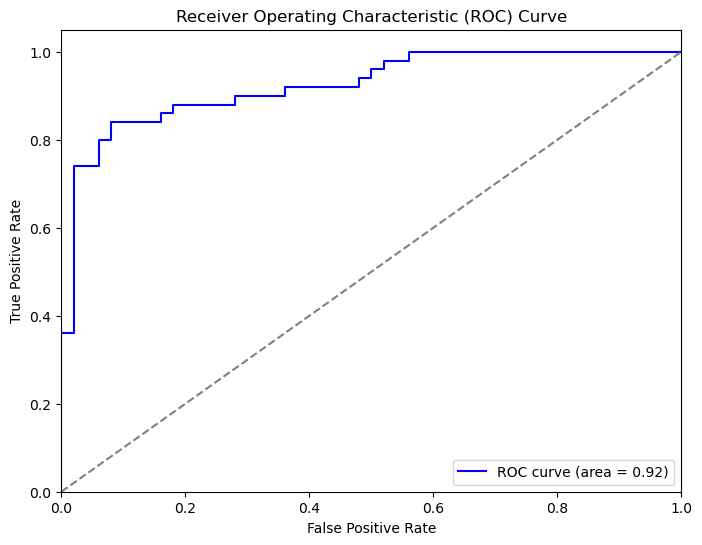

30 8 0.8020202020202021
30 15 0.846547314578005
70 8 0.8
70 15 0.8
150 8 0.849624060150376
150 15 0.7506265664160401
250 8 0.7979797979797979
250 15 0.8020202020202021
Highest F1 score Random Forest: 0.849624060150376, Best Random Forest estimators: 150, Best Random Forest depth: 8
Random Forest
Accuracy: 1.0
Recall: 1.0
Precision: 1.0
Confusion Matrix:
[[50  0]
 [ 0 50]]
F1-score: 1.0


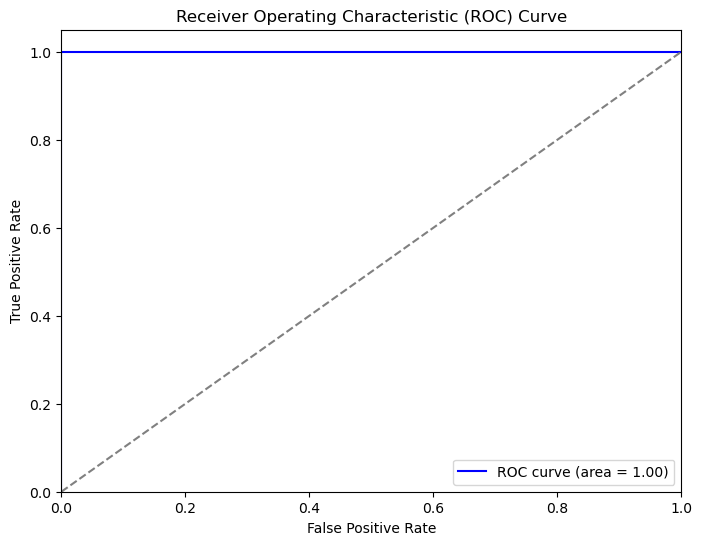

In [20]:
# Ensemble Learning methodologies

k_fold= KFold(n_splits=5, shuffle=True, random_state=25)

# Bagging
highest_f1_bagging= -1
best_bagging_estimators= None

for n_estimatorsPar in [10,20]:
    fold_f1_list_bagging= []

    for fold, (train_index, test_index) in enumerate(k_fold.split(x)):
        x_train_fold, x_test_fold = x[train_index], x[test_index]
        y_train_fold, y_test_fold = y[train_index], y[test_index]

        svm_model= SVC(kernel="linear", probability=True)
        bagging_model= BaggingClassifier(estimator=svm_model,n_estimators=n_estimatorsPar)
        y_test_pred= bagging_model.fit(x_train_fold, y_train_fold).predict(x_test_fold)

        f1= f1_score(y_test_fold, y_test_pred, average="weighted")
        fold_f1_list_bagging.append(f1)

    best_fold_score_bagging= np.max(fold_f1_list_bagging)
    print(n_estimatorsPar, best_fold_score_bagging)

    if best_fold_score_bagging > highest_f1_bagging:
        highest_f1_bagging= best_fold_score_bagging
        best_bagging_estimators= n_estimatorsPar
print(f"Highest F1 score Bagging: {highest_f1_bagging}, Best Bagging estimators: {best_bagging_estimators}")

#εφαρμοζουμε Bagging στο x kai y train
final_base_svm= SVC(kernel="linear", probability=True)
bagging_model= BaggingClassifier(estimator=final_base_svm, n_estimators=best_bagging_estimators)
y_pred_bagging= bagging_model.fit(x, y).predict(x)

accuracy= accuracy_score(y, y_pred_bagging)
recall= recall_score(y, y_pred_bagging)
conf_matrix= confusion_matrix(y, y_pred_bagging)
precision= precision_score(y, y_pred_bagging)
f1= f1_score(y, y_pred_bagging, average="weighted")

print("\nBagging")
print(f"Accuracy: {accuracy}")
print(f"Recall: {recall}")
print(f"Confusion Matrix:\n{conf_matrix}")
print(f"Precision: {precision}")
print(f"F1-score: {f1}")

fpr, tpr, thresholds= roc_curve(y, bagging_model.predict_proba(x)[:, 1])
roc_auc= auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color="blue", label=f"ROC curve (area = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], color="gray", linestyle="--")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Receiver Operating Characteristic (ROC) Curve")
plt.legend(loc="lower right")
plt.show()


# Random Forest
highest_f1_rf= -1
best_rf_estimators= None
best_rf_depth= None

for n_estimatorsPar in [30, 70, 150, 250]:
    for max_depthPar in [8, 15]:
        fold_f1_list_rf= []

        for fold, (train_index, test_index) in enumerate(k_fold.split(x)):
            x_train_fold, x_test_fold = x[train_index], x[test_index]
            y_train_fold, y_test_fold = y[train_index], y[test_index]

            rf_model= RandomForestClassifier(n_estimators=n_estimatorsPar, max_depth=max_depthPar)
            y_test_pred= rf_model.fit(x_train_fold, y_train_fold).predict(x_test_fold)

            f1= f1_score(y_test_fold, y_test_pred, average="weighted")
            fold_f1_list_rf.append(f1)

    
        best_fold_score_rf= np.max(fold_f1_list_rf)
        print(n_estimatorsPar, max_depthPar, best_fold_score_rf)

        if best_fold_score_rf > highest_f1_rf:
            highest_f1_rf= best_fold_score_rf
            best_rf_estimators= n_estimatorsPar
            best_rf_depth= max_depthPar
print(f"Highest F1 score Random Forest: {highest_f1_rf}, Best Random Forest estimators: {best_rf_estimators}, Best Random Forest depth: {best_rf_depth}")

#εφαρμοζουμε Random Forest στο x kai y train
rf_model= RandomForestClassifier(n_estimators=best_rf_estimators, max_depth=best_rf_depth)
y_pred_rf= rf_model.fit(x, y).predict(x)


accuracy = accuracy_score(y, y_pred_rf)
recall = recall_score(y, y_pred_rf)
conf_matrix = confusion_matrix(y, y_pred_rf)
precision = precision_score(y, y_pred_rf)
f1 = f1_score(y, y_pred_rf, average="weighted")

print("Random Forest")
print(f"Accuracy: {accuracy}")
print(f"Recall: {recall}")
print(f"Precision: {precision}")
print(f"Confusion Matrix:\n{conf_matrix}")
print(f"F1-score: {f1}")

fpr, tpr, thresholds= roc_curve(y, rf_model.predict_proba(x)[:, 1])
roc_auc= auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color="blue", label=f"ROC curve (area = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], color="gray", linestyle="--")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Receiver Operating Characteristic (ROC) Curve")
plt.legend(loc="lower right")
plt.show()

# Δημιουργία αρχείου υποβολής με τις προβλέψεις του Random Forest μοντέλου για τα δεδομένα validation
y_pred_prob = rf_model.predict(validation)  # ή bagging ή rf

results_df = pd.DataFrame({
     "ID": test_ids,
     "LABEL": y_pred_prob.flatten()  # single value for each prediction
 })

results_df["LABEL"] = results_df["LABEL"].apply(lambda x: 1 if x >= 0.5 else 0)
results_df.to_csv("preds.csv", index=False)
results_df.to_excel("preds.xlsx", index=False)


In [ ]:
#CNN
k_fold= KFold(n_splits=5, shuffle=True, random_state=25)

best_f1= -1
best_trained_model= None
best_hyperparameters= None

for dense_layers in [1,3]:
    for dropout_rate in [0.2, 0.3, 0.5]:
        for batchSIZE in [16, 32, 64]:
            list_of_scores= []

            for fold, (train_index, test_index) in enumerate(k_fold.split(x)):
                x_train_fold, x_test_fold = x[train_index], x[test_index]
                y_train_fold, y_test_fold = y[train_index], y[test_index]

                # orismos CNN montelou 
                model= Sequential()
                model.add(Input(shape=(64, 64, 3)))  # To megethos kathe eikonas 64x64 

                # 1o convolutional layer
                model.add(Conv2D(64, (3, 3), activation="relu"))  
                model.add(BatchNormalization())
                model.add(MaxPooling2D(pool_size=(2, 2)))

                # 2o convolutional layer
                model.add(Conv2D(128, (3, 3), activation="relu")) 
                model.add(BatchNormalization())
                model.add(MaxPooling2D(pool_size=(2, 2)))

                model.add(Flatten())

                # dense layers (Fully Connected)
                for _ in range(dense_layers):
                    model.add(Dense(256, activation="relu")) #Add a layer with 256 neurons
                    model.add(Dropout(dropout_rate))

                #The last layer that gives the awnser
                model.add(Dense(1, activation="sigmoid"))

                model.compile(optimizer=Adam(), loss="binary_crossentropy", metrics=["accuracy"])
                model.fit(x_train_fold, y_train_fold, epochs=50, batch_size=batchSIZE, verbose=0) # fit = ekpaideysi

                #The result/prediction! If the posibility > 0.5 -> 1 (happy) otherwise 0 (sad)
                y_test_pred= (model.predict(x_test_fold) > 0.5).astype(int) # predict = provlepsi

                current_score= f1_score(y_test_fold, y_test_pred, average="weighted")
                list_of_scores.append(current_score)

            #Max score of current fold
            best_score_in_fold = np.max(list_of_scores)

            print(dense_layers, dropout_rate, batchSIZE, best_score_in_fold)

            if best_score_in_fold > best_f1:
                best_f1 = best_score_in_fold
                best_trained_model = model
                best_hyperparameters = {"dense_layers": dense_layers, "dropout_rate": dropout_rate, "batch_size": batchSIZE}
print(f"Best F1 score: {best_f1}, Best Architecture: {best_hyperparameters}")


# εφαμοργή CNN σε ολόκληρο το train dataset (x και y train)
y_pred = (best_trained_model.predict(x) > 0.5).astype(int)

recall = recall_score(y, y_pred)
accuracy = accuracy_score(y, y_pred)
precision = precision_score(y, y_pred)
conf_matrix = confusion_matrix(y, y_pred)
current_score = f1_score(y, y_pred, average="weighted")

print(f"F1-score: {current_score}")
print(f"Recall: {recall}")
print(f"Accuracy: {accuracy}")
print(f"Precision: {precision}")
print(f"Confusion Matrix:\n{conf_matrix}")

fpr, tpr, thresholds = roc_curve(y, best_trained_model.predict(x))
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color="blue", label=f"ROC curve (area = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], color="gray", linestyle="--")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Receiver Operating Characteristic (ROC) Curve")
plt.legend(loc="lower right")
plt.show()


# Δημιουργία αρχείου υποβολής με τις προβλέψεις του CNN μοντέλου για τα δεδομένα validation
y_pred_prob = best_trained_model.predict(validation)

results_df = pd.DataFrame({
     "ID": test_ids,
     "LABEL": y_pred_prob.flatten()  # single value for each prediction
})

results_df["LABEL"] = results_df["LABEL"].apply(lambda x: 1 if x >= 0.5 else 0)
results_df.to_csv("preds.csv", index=False)
results_df.to_excel("preds.xlsx", index=False)


3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step
2/3 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step WARNING:tensorflow:6 out of the last 9 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x00000184525E5B20> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step
1 0.2 16 0.8
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 